# 04_1. 예외 케이스 시각 검토

`04_case_review_registry.csv`에 등록된 예외를 사람이 판단할 수 있도록 메타데이터와 비교 영상을 표시합니다. 원본 NIfTI와 승인 CSV는 수정하지 않습니다.

- `AFFINE_MISMATCH`: voxel 배열 기준 overlay와 world-coordinate resampling 결과를 비교합니다.
- `INTENSITY_SIGNED12`: 원본과 signed 12-bit 후보 변환의 통계, histogram, 동일 slice를 비교합니다.
- `Z_SPACING_OUTLIER`: spacing, 물리적 촬영 범위와 여러 연속 slice를 확인합니다.

> 이 노트북의 그림만으로 확정할 수 없는 사례는 `04_case_review_registry.csv`에서 `EXCLUDE`하거나 `approved=False`로 유지하세요.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import nibabel as nib
from nibabel.processing import resample_from_to
import numpy as np
import pandas as pd
from IPython.display import display

# Windows/VS Code에서 그림 제목의 한글이 깨지지 않도록 설정합니다.
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / 'project_config.json').is_file() and (candidate / 'ctqa_utils.py').is_file():
            return candidate
    raise FileNotFoundError('project_config.json이 있는 프로젝트 폴더를 여세요.')

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
from ctqa_utils import array_summary, effective_affine, read_nifti_data, read_nifti_header, sampled_percentiles

RESULTS = PROJECT_ROOT / 'results'
FIGURES = RESULTS / '04_1_review_figures'
FIGURES.mkdir(exist_ok=True)
pairs = pd.read_csv(RESULTS / '00_pair_manifest.csv').fillna('')
registry = pd.read_csv(RESULTS / '04_case_review_registry.csv').fillna('')
print('검토 대상:', len(registry), '건')
display(registry[['source', 'case_id', 'issue', 'evidence', 'allowed_actions']])

검토 대상: 6 건


,source,case_id,issue,evidence,allowed_actions
0,BHSD,ID_089596a9_ID_ea71b57820,AFFINE_MISMATCH,"{""affine_max_abs_diff"": 0.3871440922309828, ""i...",COPY_CT_AFFINE_TO_MASK|RESAMPLE_MASK_TO_CT|EXC...
1,BHSD,ID_56faaf6f_ID_dd8f688dff,Z_SPACING_OUTLIER,"{""z_spacing_mm"": 0.5, ""source_median_mm"": 5.03...",KEEP_CONFIRMED|EXCLUDE
2,BHSD,ID_727c946e_ID_e1fd84171a,AFFINE_MISMATCH,"{""affine_max_abs_diff"": 0.8620945796618293, ""i...",COPY_CT_AFFINE_TO_MASK|RESAMPLE_MASK_TO_CT|EXC...
3,BHSD,ID_88dbe13f_ID_01c5078fbf,AFFINE_MISMATCH,"{""affine_max_abs_diff"": 0.8036462317956217, ""i...",COPY_CT_AFFINE_TO_MASK|RESAMPLE_MASK_TO_CT|EXC...
4,BHSD,ID_a429fd9a_ID_2eabc43f3d,INTENSITY_SIGNED12,"{""min"": 0.0, ""p50"": 3096.0, ""p99"": 4078.0, ""ma...",APPLY_SIGNED12|KEEP_CONFIRMED|EXCLUDE
5,BHSD,ID_cb4c887c_ID_ec2a4643f3,AFFINE_MISMATCH,"{""affine_max_abs_diff"": 0.5016892679503235, ""i...",COPY_CT_AFFINE_TO_MASK|RESAMPLE_MASK_TO_CT|EXC...


## 공통 함수

빨간색은 원본 mask, 청록색은 CT 좌표계로 nearest-neighbor resampling한 mask입니다. 그림은 `results/04_1_review_figures`에도 저장됩니다.

In [2]:
def case_paths(source, case_id):
    hit = pairs[(pairs.source == source) & (pairs.case_id.astype(str) == str(case_id))]
    if len(hit) != 1:
        raise KeyError(f'pair manifest에서 사례를 하나로 찾지 못했습니다: {source}/{case_id}')
    row = hit.iloc[0]
    return Path(row.image_path), Path(row.mask_path)

def load_case(source, case_id):
    image_path, mask_path = case_paths(source, case_id)
    ih, mh = read_nifti_header(image_path), read_nifti_header(mask_path)
    ct = np.asarray(read_nifti_data(image_path, ih, scaled=True), dtype=np.float32)
    mask = np.asarray(read_nifti_data(mask_path, mh, scaled=True))
    ia, ia_source = effective_affine(ih)
    ma, ma_source = effective_affine(mh)
    return image_path, mask_path, ih, mh, ia, ma, ia_source, ma_source, ct, mask

def representative_slices(mask, count=3):
    positive = np.flatnonzero((mask > 0).sum(axis=(0, 1)) > 0)
    if len(positive):
        indices = np.linspace(0, len(positive) - 1, min(count, len(positive))).round().astype(int)
        return [int(positive[i]) for i in indices]
    return [int(x) for x in np.linspace(0, mask.shape[2] - 1, count + 2)[1:-1]]

def show_slice(ax, ct2d, mask2d=None, title='', low=-100, high=200, color='red'):
    ax.imshow(ct2d.T, cmap='gray', vmin=low, vmax=high, origin='lower')
    if mask2d is not None and np.any(mask2d > 0):
        overlay = np.ma.masked_where(mask2d.T <= 0, mask2d.T > 0)
        ax.imshow(overlay, cmap='Reds' if color == 'red' else 'winter', alpha=0.38, origin='lower', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

def save_and_show(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print('그림 저장:', path)

## 1. Affine 불일치 검토

왼쪽은 CT와 mask의 voxel index가 같다고 가정한 overlay입니다. 오른쪽은 현재 NIfTI affine을 신뢰해 mask를 CT world grid로 옮긴 결과입니다.

- 왼쪽만 해부학적으로 맞으면 `COPY_CT_AFFINE_TO_MASK` 후보입니다.
- 오른쪽이 맞으면 `RESAMPLE_MASK_TO_CT` 후보입니다.
- 둘 다 맞지 않거나 판단이 어려우면 `EXCLUDE` 또는 미승인으로 유지합니다.


[BHSD / ID_089596a9_ID_ea71b57820] AFFINE_MISMATCH
affine 최대 절대차: 0.38714409223098284


,object,shape,spacing_mm,affine_source,positive_voxels
0,CT,"(512, 512, 40)","(np.float64(0.48828), np.float64(0.5458), np.f...",sform,
1,mask raw,"(512, 512, 40)","(np.float64(0.48828), np.float64(0.48828), np....",qform,629
2,mask resampled,"(512, 512, 40)",CT와 동일,CT grid,600


CT affine:
 [[  -0.48828    0.         0.       153.5    ]
 [   0.         0.51962   -0.      -100.40263]
 [   0.         0.167      2.34923  -38.04351]
 [   0.         0.         0.         1.     ]]
mask affine:
 [[  -0.48828    0.         0.       153.5    ]
 [   0.         0.48239   -0.38714 -100.40263]
 [   0.         0.07561    2.46984  -38.04351]
 [   0.         0.         0.         1.     ]]


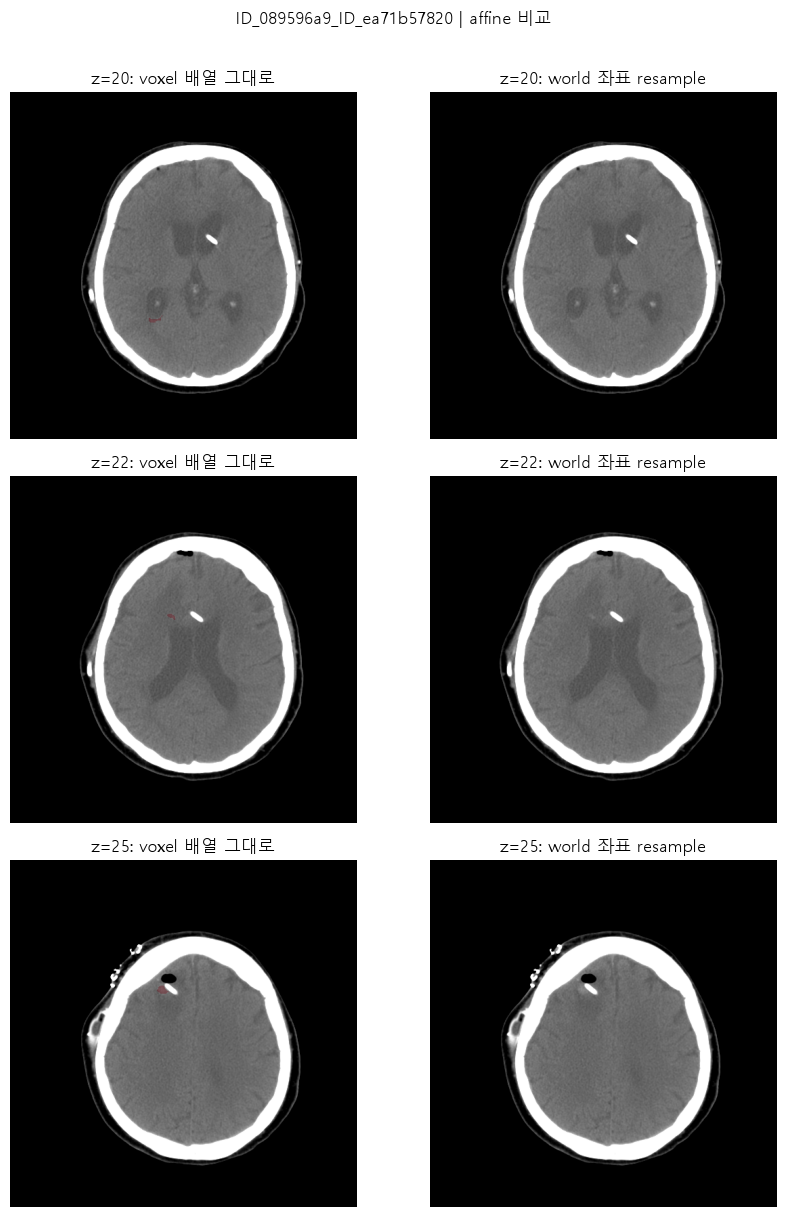

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\affine_ID_089596a9_ID_ea71b57820.png

[BHSD / ID_727c946e_ID_e1fd84171a] AFFINE_MISMATCH
affine 최대 절대차: 0.8620945796618293


,object,shape,spacing_mm,affine_source,positive_voxels
0,CT,"(512, 512, 30)","(np.float64(0.68359), np.float64(0.7892), np.f...",sform,
1,mask raw,"(512, 512, 30)","(np.float64(0.68359), np.float64(0.68359), np....",qform,1018
2,mask resampled,"(512, 512, 30)",CT와 동일,CT grid,994


CT affine:
 [[  -0.68359    0.         0.       234.     ]
 [   0.         0.74263   -0.      -307.05722]
 [   0.         0.2671     4.61976   40.52484]
 [   0.         0.         0.         1.     ]]
mask affine:
 [[  -0.68359    0.         0.       234.     ]
 [   0.         0.67343   -0.86209 -307.05722]
 [   0.         0.11742    4.94413   40.52484]
 [   0.         0.         0.         1.     ]]


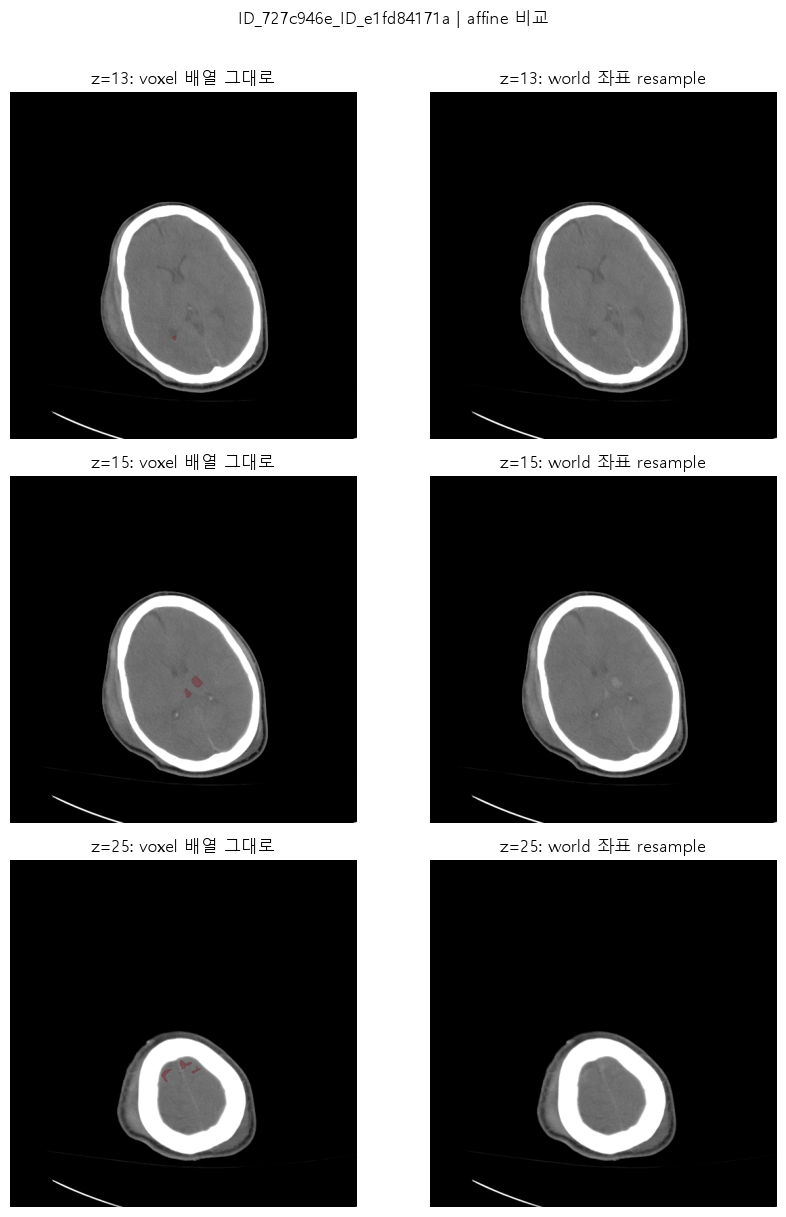

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\affine_ID_727c946e_ID_e1fd84171a.png

[BHSD / ID_88dbe13f_ID_01c5078fbf] AFFINE_MISMATCH
affine 최대 절대차: 0.8036462317956217


,object,shape,spacing_mm,affine_source,positive_voxels
0,CT,"(512, 512, 36)","(np.float64(0.48828), np.float64(0.55152), np....",sform,
1,mask raw,"(512, 512, 36)","(np.float64(0.48828), np.float64(0.48828), np....",qform,12724
2,mask resampled,"(512, 512, 36)",CT와 동일,CT grid,12802


CT affine:
 [[  -0.48828    0.         0.       125.     ]
 [   0.         0.52302   -0.      -108.44156]
 [   0.         0.17498    4.6679   -93.12687]
 [   0.         0.         0.         1.     ]]
mask affine:
 [[  -0.48828    0.         0.       125.     ]
 [   0.         0.48193   -0.80365 -108.44156]
 [   0.         0.07848    4.93499  -93.12687]
 [   0.         0.         0.         1.     ]]


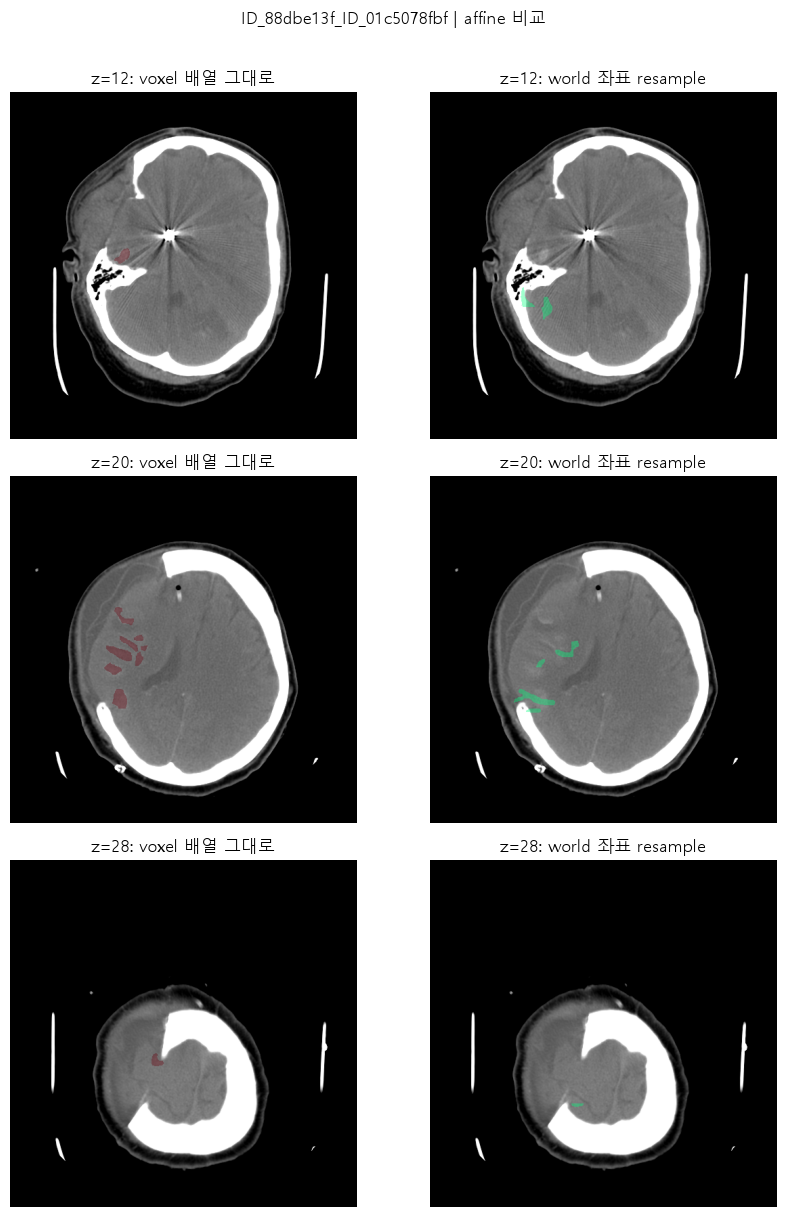

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\affine_ID_88dbe13f_ID_01c5078fbf.png

[BHSD / ID_cb4c887c_ID_ec2a4643f3] AFFINE_MISMATCH
affine 최대 절대차: 0.5016892679503235


,object,shape,spacing_mm,affine_source,positive_voxels
0,CT,"(512, 512, 30)","(np.float64(0.48828), np.float64(0.50941), np....",sform,
1,mask raw,"(512, 512, 30)","(np.float64(0.48828), np.float64(0.48828), np....",qform,10555
2,mask resampled,"(512, 512, 30)",CT와 동일,CT grid,10585


CT affine:
 [[  -0.48828    0.         0.       125.     ]
 [   0.         0.49919   -0.      -265.09338]
 [   0.         0.10152    4.90001 -190.57608]
 [   0.         0.         0.         1.     ]]
mask affine:
 [[  -0.48828    0.         0.       125.     ]
 [   0.         0.48583   -0.50169 -265.09338]
 [   0.         0.0489     4.9843  -190.57608]
 [   0.         0.         0.         1.     ]]


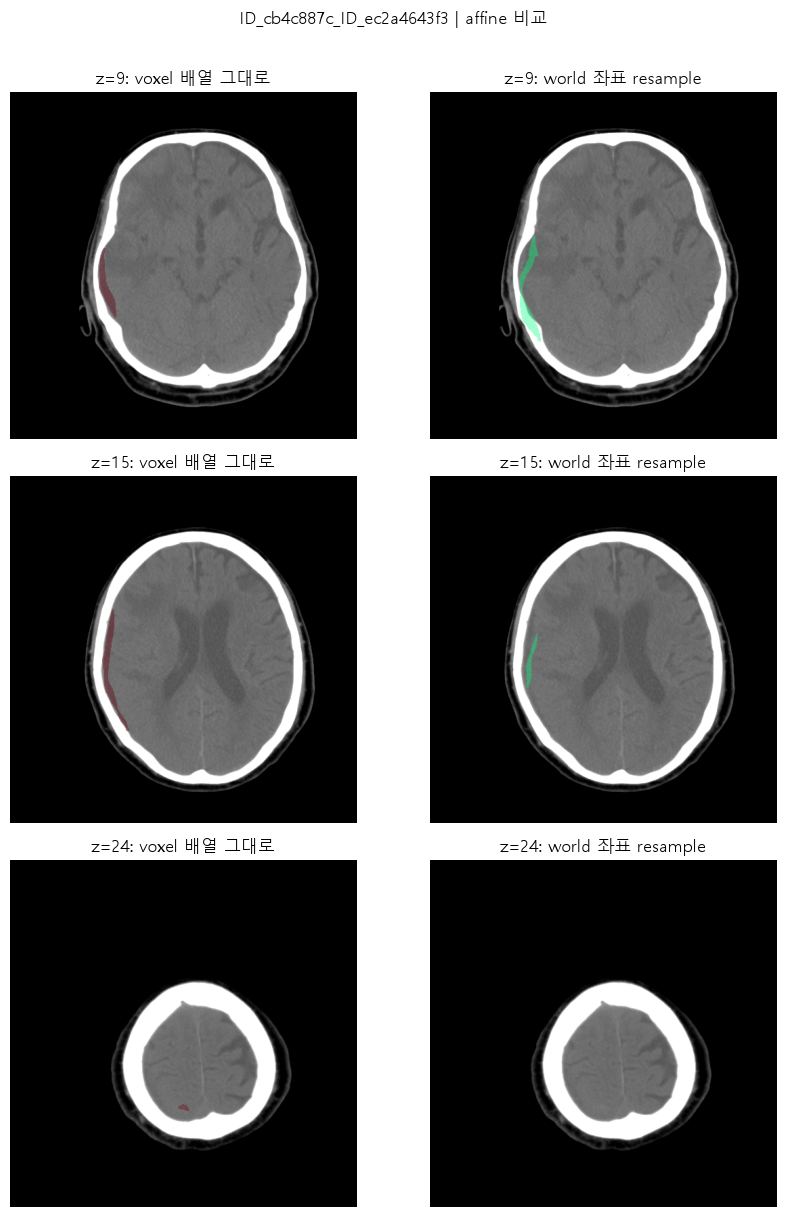

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\affine_ID_cb4c887c_ID_ec2a4643f3.png


In [3]:
def review_affine(source, case_id):
    image_path, mask_path, ih, mh, ia, ma, ia_src, ma_src, ct, mask = load_case(source, case_id)
    ct_img = nib.load(str(image_path))
    mask_img = nib.load(str(mask_path))
    resampled_img = resample_from_to(mask_img, (ct_img.shape, ct_img.affine), order=0, mode='constant', cval=0)
    resampled = np.asarray(resampled_img.get_fdata(dtype=np.float32))
    metadata = pd.DataFrame([
        {'object': 'CT', 'shape': str(ct.shape), 'spacing_mm': str(tuple(np.round(np.linalg.norm(ia[:3, :3], axis=0), 5))), 'affine_source': ia_src, 'positive_voxels': ''},
        {'object': 'mask raw', 'shape': str(mask.shape), 'spacing_mm': str(tuple(np.round(np.linalg.norm(ma[:3, :3], axis=0), 5))), 'affine_source': ma_src, 'positive_voxels': int((mask > 0).sum())},
        {'object': 'mask resampled', 'shape': str(resampled.shape), 'spacing_mm': 'CT와 동일', 'affine_source': 'CT grid', 'positive_voxels': int((resampled > 0).sum())},
    ])
    print(f'\n[{source} / {case_id}] AFFINE_MISMATCH')
    print('affine 최대 절대차:', float(np.max(np.abs(ia - ma))))
    display(metadata)
    print('CT affine:\n', np.array2string(ia, precision=5, suppress_small=True))
    print('mask affine:\n', np.array2string(ma, precision=5, suppress_small=True))
    zs = representative_slices(mask)
    fig, axes = plt.subplots(len(zs), 2, figsize=(9, 4 * len(zs)), squeeze=False)
    for r, z in enumerate(zs):
        show_slice(axes[r, 0], ct[:, :, z], mask[:, :, z], f'z={z}: voxel 배열 그대로', color='red')
        show_slice(axes[r, 1], ct[:, :, z], resampled[:, :, z], f'z={z}: world 좌표 resample', color='cyan')
    fig.suptitle(f'{case_id} | affine 비교', y=1.01)
    fig.tight_layout()
    save_and_show(fig, f'affine_{case_id}.png')

for row in registry[registry.issue == 'AFFINE_MISMATCH'].itertuples():
    review_affine(row.source, row.case_id)

## 2. Signed 12-bit 강도 후보 검토

후보 변환은 `value > 2047`인 voxel에서 4096을 뺍니다. 원본 파일에는 쓰지 않고 메모리에서만 비교합니다. 변환 후 공기 약 -1000 HU, 연부조직 수십 HU, 뼈 높은 양수의 분포가 자연스러운지 봅니다.


[BHSD / ID_a429fd9a_ID_2eabc43f3d] INTENSITY_SIGNED12
stored dtype: <i2 | slope/intercept: 1.0 0.0


,version,finite_fraction,min,max,p01,p50,p99
0,original scaled,1.0,0.0,4095.0,11.0,3096.0,4078.0
1,signed12 candidate,1.0,-2010.0,1994.0,-1000.0,-986.0,1218.0


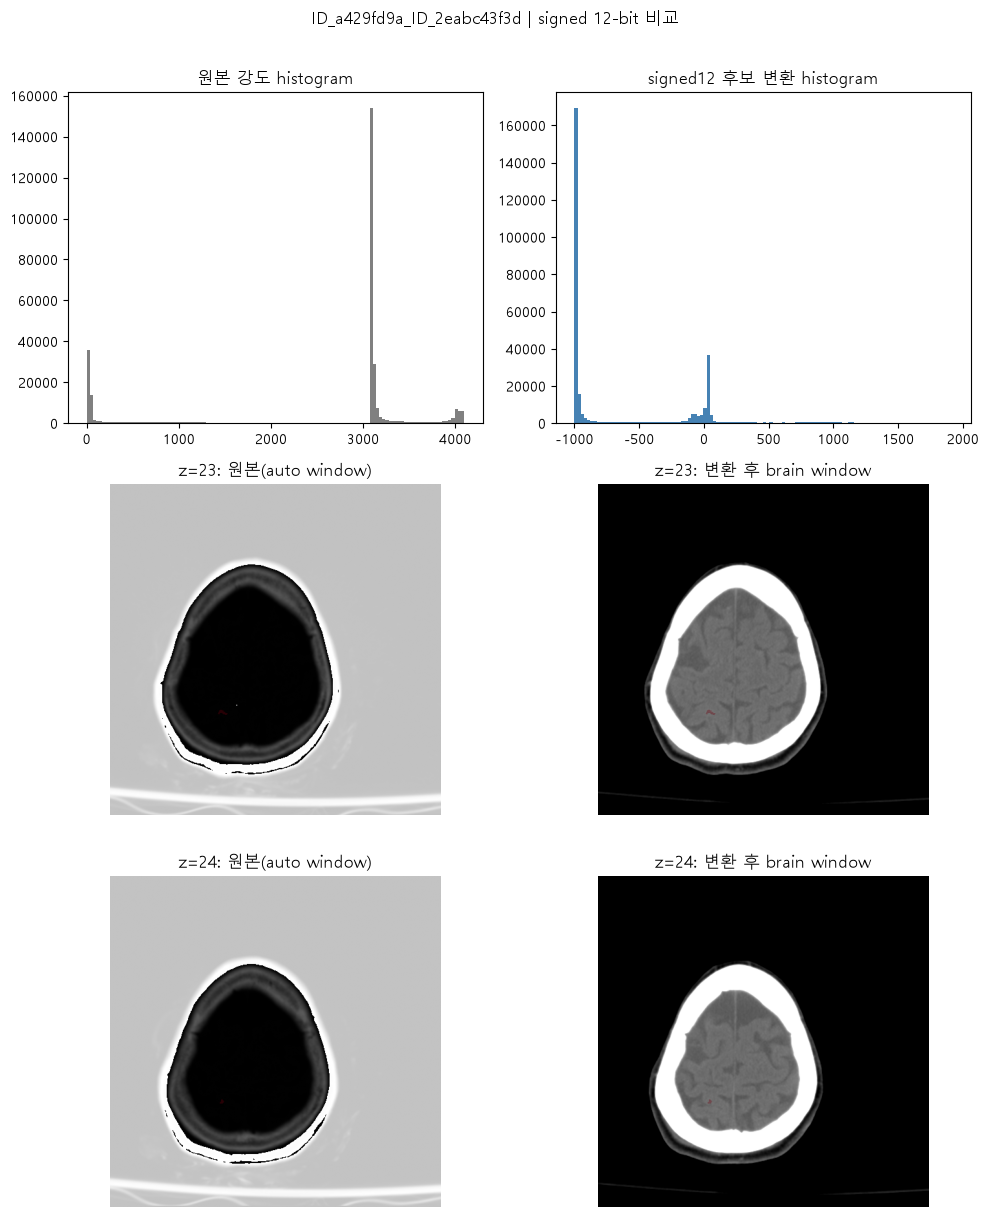

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\intensity_ID_a429fd9a_ID_2eabc43f3d.png


In [4]:
def review_intensity(source, case_id):
    _, _, ih, _, _, _, _, _, ct, mask = load_case(source, case_id)
    corrected = np.where(ct > 2047, ct - 4096, ct).astype(np.float32)
    summary = pd.DataFrame([
        {'version': 'original scaled', **array_summary(ct, percentiles=(1, 50, 99))},
        {'version': 'signed12 candidate', **array_summary(corrected, percentiles=(1, 50, 99))},
    ])
    print(f'\n[{source} / {case_id}] INTENSITY_SIGNED12')
    print('stored dtype:', ih['dtype'], '| slope/intercept:', ih['scl_slope'], ih['scl_inter'])
    display(summary)
    flat_original = ct.reshape(-1)[::max(1, ct.size // 300000)]
    flat_corrected = corrected.reshape(-1)[::max(1, corrected.size // 300000)]
    zs = representative_slices(mask)
    fig, axes = plt.subplots(len(zs) + 1, 2, figsize=(10, 4 * (len(zs) + 1)), squeeze=False)
    axes[0, 0].hist(flat_original[np.isfinite(flat_original)], bins=120, color='gray')
    axes[0, 0].set_title('원본 강도 histogram')
    axes[0, 1].hist(flat_corrected[np.isfinite(flat_corrected)], bins=120, color='steelblue')
    axes[0, 1].set_title('signed12 후보 변환 histogram')
    for r, z in enumerate(zs, start=1):
        lo, hi = sampled_percentiles(ct[:, :, z], (1, 99))
        show_slice(axes[r, 0], ct[:, :, z], mask[:, :, z], f'z={z}: 원본(auto window)', low=lo, high=hi)
        show_slice(axes[r, 1], corrected[:, :, z], mask[:, :, z], f'z={z}: 변환 후 brain window', low=-100, high=200)
    fig.suptitle(f'{case_id} | signed 12-bit 비교', y=1.01)
    fig.tight_layout()
    save_and_show(fig, f'intensity_{case_id}.png')

for row in registry[registry.issue == 'INTENSITY_SIGNED12'].itertuples():
    review_intensity(row.source, row.case_id)

## 3. z-spacing 이상치 검토

slice 수와 spacing을 곱한 대략적인 z축 촬영 범위, source 중앙값과의 차이, volume 전반의 영상을 확인합니다. 0.5 mm처럼 얇은 절편도 실제 데이터일 수 있으므로 값이 다르다는 이유만으로 오류로 확정하지 않습니다.


[BHSD / ID_56faaf6f_ID_dd8f688dff] Z_SPACING_OUTLIER


,shape,spacing_mm,approx_extent_mm,source_z_median_mm,z_ratio_to_median,CT_affine_source
0,"(512, 512, 48)","(np.float64(0.48828), np.float64(0.48828), np....","(np.float64(250.0), np.float64(250.0), np.floa...",5.035001,0.099305,sform


같은 source의 z-spacing 분포:


,count,mean,std,min,1%,25%,50%,75%,99%,max
z_spacing_mm,192.0,4.917419,0.902159,0.5,2.5,5.0,5.035001,5.334074,6.428846,6.518188


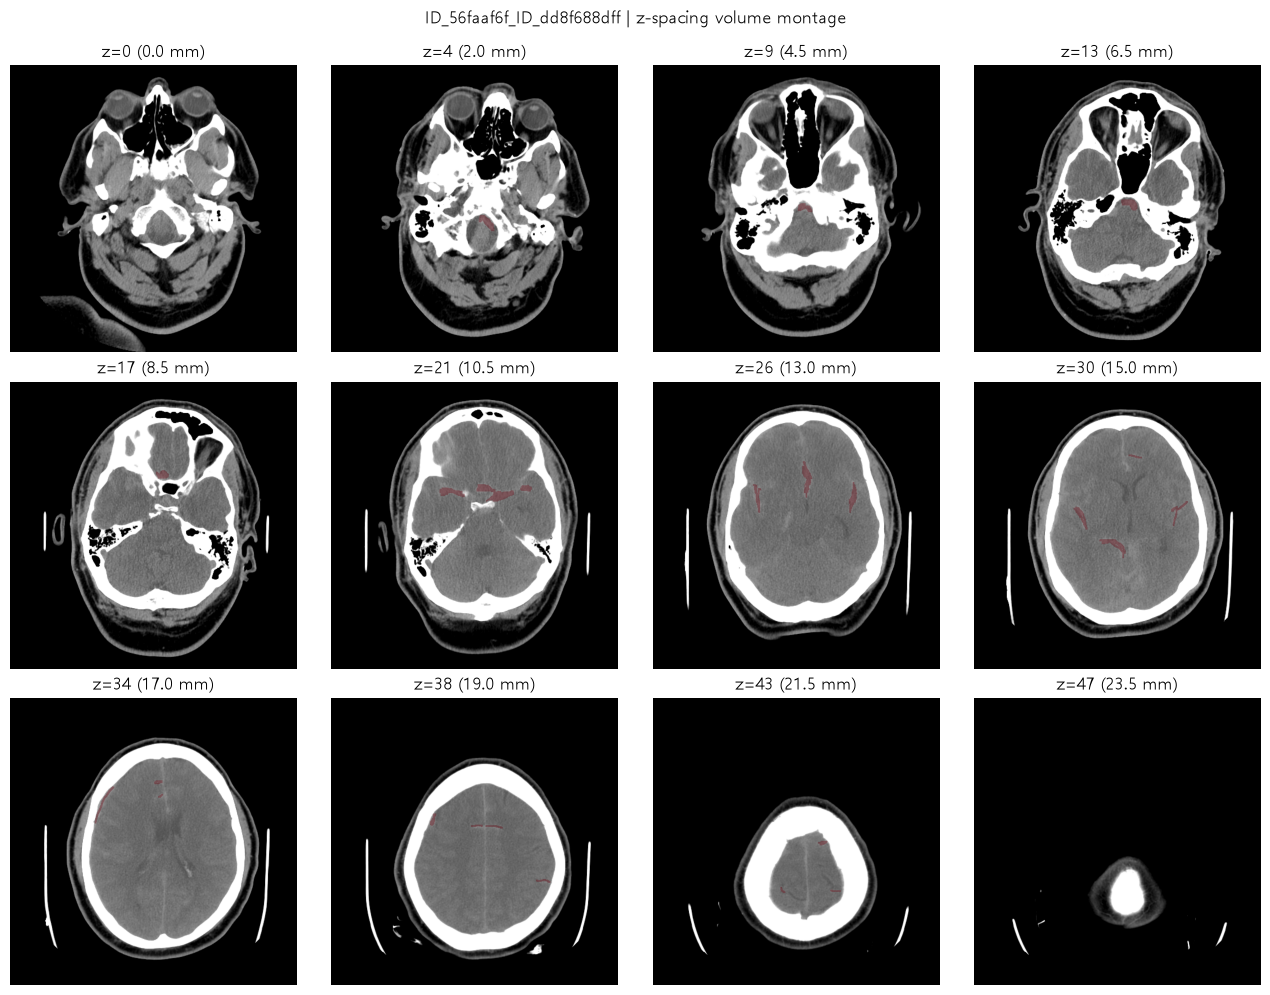

그림 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_1_review_figures\zspacing_ID_56faaf6f_ID_dd8f688dff.png


In [5]:
geometry = pd.read_csv(RESULTS / '01_geometry_checks.csv')
source_z_medians = geometry.groupby('source').z_spacing_mm.median().to_dict()

def review_z_spacing(source, case_id):
    _, _, ih, mh, ia, ma, ia_src, ma_src, ct, mask = load_case(source, case_id)
    spacing = np.linalg.norm(ia[:3, :3], axis=0)
    extent = spacing * np.asarray(ct.shape)
    comparison = geometry[geometry.source == source].z_spacing_mm.describe(percentiles=[.01, .25, .5, .75, .99])
    print(f'\n[{source} / {case_id}] Z_SPACING_OUTLIER')
    display(pd.DataFrame([{
        'shape': str(ct.shape),
        'spacing_mm': str(tuple(np.round(spacing, 5))),
        'approx_extent_mm': str(tuple(np.round(extent, 1))),
        'source_z_median_mm': source_z_medians[source],
        'z_ratio_to_median': float(spacing[2] / source_z_medians[source]),
        'CT_affine_source': ia_src,
    }]))
    print('같은 source의 z-spacing 분포:')
    display(comparison.to_frame('z_spacing_mm').T)
    zs = [int(x) for x in np.linspace(0, ct.shape[2] - 1, 12).round()]
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for ax, z in zip(axes.flat, zs):
        show_slice(ax, ct[:, :, z], mask[:, :, z], f'z={z} ({z * spacing[2]:.1f} mm)')
    fig.suptitle(f'{case_id} | z-spacing volume montage', y=0.99)
    fig.tight_layout()
    save_and_show(fig, f'zspacing_{case_id}.png')

for row in registry[registry.issue == 'Z_SPACING_OUTLIER'].itertuples():
    review_z_spacing(row.source, row.case_id)

## 4. 검토 기록 작성 안내

그림과 수치를 검토한 뒤 `results/04_case_review_registry.csv`의 다음 네 열만 작성합니다.

- `action`: 해당 행의 `allowed_actions` 중 정확히 하나
- `approved`: 판단을 완료한 경우 `True`
- `reviewer`: 검토자 이름
- `rationale`: 어떤 그림·수치로 판단했는지 구체적으로 기록

작성 후 원래 `04_예외케이스_판정_및_통합정책.ipynb`의 **3. 승인 상태 검증** 셀을 다시 실행하세요. 이 노트북은 승인값을 자동으로 작성하지 않습니다.

In [6]:
decision_guide = pd.DataFrame([
    {'issue': 'AFFINE_MISMATCH', 'observation': 'voxel 배열 overlay만 정확함', 'candidate_action': 'COPY_CT_AFFINE_TO_MASK'},
    {'issue': 'AFFINE_MISMATCH', 'observation': 'world resample overlay가 정확함', 'candidate_action': 'RESAMPLE_MASK_TO_CT'},
    {'issue': 'AFFINE_MISMATCH', 'observation': '둘 다 불명확함', 'candidate_action': 'EXCLUDE 또는 approved=False'},
    {'issue': 'INTENSITY_SIGNED12', 'observation': '변환 후 HU와 해부학적 조직 분포가 타당하고 근거가 충분함', 'candidate_action': 'APPLY_SIGNED12'},
    {'issue': 'INTENSITY_SIGNED12', 'observation': '원본이 맞다는 외부 근거가 있음', 'candidate_action': 'KEEP_CONFIRMED'},
    {'issue': 'INTENSITY_SIGNED12', 'observation': 'DICOM/변환 이력 없이 확정 불가', 'candidate_action': 'EXCLUDE 또는 approved=False'},
    {'issue': 'Z_SPACING_OUTLIER', 'observation': '얇은 절편 volume이 자연스럽고 헤더/문서 근거가 있음', 'candidate_action': 'KEEP_CONFIRMED'},
    {'issue': 'Z_SPACING_OUTLIER', 'observation': 'spacing을 신뢰하기 어려움', 'candidate_action': 'EXCLUDE 또는 approved=False'},
])
display(decision_guide)

,issue,observation,candidate_action
0,AFFINE_MISMATCH,voxel 배열 overlay만 정확함,COPY_CT_AFFINE_TO_MASK
1,AFFINE_MISMATCH,world resample overlay가 정확함,RESAMPLE_MASK_TO_CT
2,AFFINE_MISMATCH,둘 다 불명확함,EXCLUDE 또는 approved=False
3,INTENSITY_SIGNED12,변환 후 HU와 해부학적 조직 분포가 타당하고 근거가 충분함,APPLY_SIGNED12
4,INTENSITY_SIGNED12,원본이 맞다는 외부 근거가 있음,KEEP_CONFIRMED
5,INTENSITY_SIGNED12,DICOM/변환 이력 없이 확정 불가,EXCLUDE 또는 approved=False
6,Z_SPACING_OUTLIER,얇은 절편 volume이 자연스럽고 헤더/문서 근거가 있음,KEEP_CONFIRMED
7,Z_SPACING_OUTLIER,spacing을 신뢰하기 어려움,EXCLUDE 또는 approved=False


In [7]:
from pathlib import Path
import pandas as pd

registry_path = RESULTS / "04_case_review_registry.csv"
registry = pd.read_csv(registry_path).fillna("")

REVIEWER = "김호영"  # 본인 이름으로 수정

decisions = {
    "ID_089596a9_ID_ea71b57820": {
        "action": "COPY_CT_AFFINE_TO_MASK",
        "rationale": (
            "CT-mask shape가 같고 voxel 배열 기준 overlay가 병변 위치에 일치하지만 "
            "world-coordinate resampling 시 mask가 이동하므로 CT affine을 mask에 복사"
        ),
    },
    "ID_727c946e_ID_e1fd84171a": {
        "action": "COPY_CT_AFFINE_TO_MASK",
        "rationale": (
            "CT-mask shape가 같고 voxel 배열 기준 mask가 CT 병변 후보와 일치하지만 "
            "world-coordinate resampling 시 mask 위치가 이동하므로 CT affine을 mask에 복사"
        ),
    },
    "ID_88dbe13f_ID_01c5078fbf": {
        "action": "COPY_CT_AFFINE_TO_MASK",
        "rationale": (
            "voxel 배열 기준 overlay가 병변 형태와 일치하고 world-coordinate resampling 시 "
            "mask가 해부학적으로 아래쪽으로 이동하여 CT affine을 mask에 복사"
        ),
    },
    "ID_cb4c887c_ID_ec2a4643f3": {
        "action": "COPY_CT_AFFINE_TO_MASK",
        "rationale": (
            "CT-mask shape가 같고 voxel 배열 기준 mask가 두개골 안쪽 병변 영역과 일치하지만 "
            "world-coordinate resampling 시 위치가 이동하므로 CT affine을 mask에 복사"
        ),
    },
    "ID_a429fd9a_ID_2eabc43f3d": {
        "action": "APPLY_SIGNED12",
        "rationale": (
            "원본 값이 0~4095에 집중되어 일반 HU 분포와 맞지 않고 signed12 변환 후 "
            "공기 약 -1000 HU 및 정상적인 CT 조직 대비가 복원되어 변환을 적용"
        ),
    },
    "ID_56faaf6f_ID_dd8f688dff": {
        "action": "EXCLUDE",
        "rationale": (
            "48개 slice와 0.5 mm spacing으로 계산된 z축 범위는 약 24 mm이나 영상은 "
            "머리 전체를 포함하며, 원본 DICOM 없이 실제 spacing을 복원할 수 없어 제외"
        ),
    },
}

for case_id, decision in decisions.items():
    matched = registry["case_id"].astype(str) == case_id

    if matched.sum() != 1:
        raise RuntimeError(
            f"{case_id}: 검토 레지스트리에서 정확히 1건을 찾지 못했습니다."
        )

    registry.loc[matched, "action"] = decision["action"]
    registry.loc[matched, "approved"] = True
    registry.loc[matched, "reviewer"] = REVIEWER
    registry.loc[matched, "rationale"] = decision["rationale"]

registry.to_csv(
    registry_path,
    index=False,
    encoding="utf-8-sig",
)

print("검토 결과를 저장했습니다:", registry_path)
display(
    registry[
        ["source", "case_id", "issue", "action",
         "approved", "reviewer", "rationale"]
    ]
)

검토 결과를 저장했습니다: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\04_case_review_registry.csv


,source,case_id,issue,action,approved,reviewer,rationale
0,BHSD,ID_089596a9_ID_ea71b57820,AFFINE_MISMATCH,COPY_CT_AFFINE_TO_MASK,True,김호영,CT-mask shape가 같고 voxel 배열 기준 overlay가 병변 위치에 ...
1,BHSD,ID_56faaf6f_ID_dd8f688dff,Z_SPACING_OUTLIER,EXCLUDE,True,김호영,48개 slice와 0.5 mm spacing으로 계산된 z축 범위는 약 24 mm...
2,BHSD,ID_727c946e_ID_e1fd84171a,AFFINE_MISMATCH,COPY_CT_AFFINE_TO_MASK,True,김호영,CT-mask shape가 같고 voxel 배열 기준 mask가 CT 병변 후보와 ...
3,BHSD,ID_88dbe13f_ID_01c5078fbf,AFFINE_MISMATCH,COPY_CT_AFFINE_TO_MASK,True,김호영,voxel 배열 기준 overlay가 병변 형태와 일치하고 world-coordin...
4,BHSD,ID_a429fd9a_ID_2eabc43f3d,INTENSITY_SIGNED12,APPLY_SIGNED12,True,김호영,원본 값이 0~4095에 집중되어 일반 HU 분포와 맞지 않고 signed12 변환...
5,BHSD,ID_cb4c887c_ID_ec2a4643f3,AFFINE_MISMATCH,COPY_CT_AFFINE_TO_MASK,True,김호영,CT-mask shape가 같고 voxel 배열 기준 mask가 두개골 안쪽 병변 ...
